# Mecânica dos Fluidos — Projeto 1
## Escoamento de Hagen–Poiseuille: da modelagem física à solução pelo Método dos Elementos Finitos

### Objetivo
Estudar o escoamento laminar em um tubo cilíndrico, partindo da dedução física [Nussenzveig, 2004] e desenvolvendo a formulação variacional, a solução pelo MEF/FEniCSx e sua verificação.

$$
\boxed{\text{problema físico}\to\text{modelo}\to\text{solução analítica}\to\text{forma fraca}\to\text{MEF}\to\text{FEniCSx}\to\text{verificação}}
$$

### 1. O Problema Físico (Seção 2)

Imagine um cano cilíndrico reto de raio $a$ e comprimento $l$. Você aplica uma pressão maior na entrada ($p_1$) do que na saída ($p_2$), empurrando o fluido para a frente. Ao mesmo tempo, o fluido tem **viscosidade** ($\eta$), que funciona como um atrito interno entre as "camadas" cilíndricas de fluido que deslizam umas sobre as outras.

**1. Por que $v$ depende apenas de $r$?**
Em coordenadas cilíndricas $(r, \theta, z)$, a velocidade poderia depender das três variáveis e do tempo. Contudo, pelas hipóteses do problema:


* *Estacionário:* não muda no tempo ($\partial v/\partial t = 0$).
* *Axisimétrico:* o tubo é perfeitamente redondo e não há rotação; o escoamento é idêntico em qualquer ângulo ($\partial v/\partial \theta = 0$).
* *Incompressível e plenamente desenvolvido:* longe da entrada do tubo, o perfil de velocidade se estabiliza e não muda mais ao longo do eixo $z$ ($\partial v/\partial z = 0$). Logo, sobra apenas a distância ao centro: $v = v(r)$.




**2. Por que $v(a) = 0$?**
* Pela **condição de não-escorregamento** (*no-slip condition*). Em fluidos viscosos, as moléculas em contato imediato com uma parede sólida aderem a ela devido às forças intermoleculares e rugosidades microscópicas. Como a parede do tubo ($r = a$) está parada, o fluido exatamente em $r = a$ tem velocidade zero.


**3. Por que não devemos impor $v(0) = 0$?**
* Porque $r = 0$ não é uma parede física; é apenas o eixo central geométrico do tubo. O fluido está escoando livremente pelo meio do cano. Impor $v(0) = 0$ equivaleria fisicamente a passar um fio sólido estacionário bem no centro do tubo, alterando completamente o problema físico (viraria um escoamento anular).


**4. Onde se espera a velocidade máxima?**
* Exatamente no eixo central do tubo ($r = 0$), pois é a região mais distante das paredes estacionárias onde o efeito de frenagem viscosa é mínimo. Por simetria, a curva de velocidade faz um "pico" suave no centro, o que matematicamente significa derivada nula: $\left.\frac{dv}{dr}\right\vert{}_{r=0} = 0$.



---

### 2. Dedução da Solução Analítica e Vazão (Seções 3 e 4)

Seguindo a formulação de Nussenzveig, tomamos um cilindro imaginário de fluido de raio $r \le a$ e comprimento $l$. Como o escoamento é estacionário (sem aceleração), a soma das forças horizontais sobre esse volume cilíndrico deve ser zero:

1. **Força de pressão (empurra o fluido):** atua nas tampas circulares de área $\pi r^2$:



$$F_p = (p_1 - p_2)\pi r^2$$


2. **Força de arrasto viscoso (freia o fluido):** atua na casca lateral de área $A = 2\pi r l$. Pela lei de Newton da viscosidade, a tensão de cisalhamento é proporcional ao gradiente de velocidade ($\tau = -\eta \frac{dv}{dr}$, com sinal negativo porque $v$ diminui à medida que $r$ cresce):



$$\frac{F_p}{A} = \frac{(p_1 - p_2)\pi r^2}{2\pi r l} = \frac{p_1 - p_2}{2l}r = -\eta \frac{dv}{dr}$$



Definindo a queda de pressão por unidade de comprimento como $G = \frac{p_1 - p_2}{l}$, isolamos a derivada:


$$\frac{dv}{dr} = -\frac{G}{2\eta}r$$

**Integrando em relação a $r$ (Tarefa da Seção 3):**

$$v(r) = \int \left(-\frac{G}{2\eta}r\right) dr = -\frac{G}{4\eta}r^2 + C$$

Para descobrir a constante $C$, aplicamos a condição de contorno na parede, $v(a) = 0$:


$$v(a) = -\frac{G}{4\eta}a^2 + C = 0 \implies C = \frac{G}{4\eta}a^2$$

Substituindo $C$, chegamos ao **perfil parabólico de Hagen–Poiseuille**:


$$v_{\text{exato}}(r) = \frac{G}{4\eta}(a^2 - r^2)$$

**Dedução da Vazão Volumétrica $Q_{\text{exato}}$ (Seção 4 e Seção 16):**
A vazão é a integral da velocidade na seção transversal do tubo. Como a velocidade é constante ao longo de um anel fino de raio $r$ e espessura $dr$, a área infinitesimal desse anel é $dA = (\text{circunferência}) \times (\text{espessura}) = 2\pi r \, dr$. Integrando de $0$ até $a$:


$$Q_{\text{exato}} = \int_0^a v_{\text{exato}}(r) \, dA = \int_0^a \frac{G}{4\eta}(a^2 - r^2) \cdot 2\pi r \, dr = \frac{\pi G}{2\eta} \int_0^a (a^2 r - r^3) \, dr$$

$$Q_{\text{exato}} = \frac{\pi G}{2\eta} \left[ \frac{a^2 r^2}{2} - \frac{r^4}{4} \right]_0^a = \frac{\pi G}{2\eta} \left( \frac{a^4}{2} - \frac{a^4}{4} \right) = \frac{\pi a^4 G}{8\eta}$$

---

### 3. Da Equação Diferencial à Forma Fraca (Seção 5)

No Método dos Elementos Finitos (MEF), não resolvemos a equação diferencial diretamente ("forma forte"), mas sim uma versão integral equivalente chamada **forma fraca** (ou variacional).

A equação diferencial do escoamento axial em coordenadas cilíndricas (forma forte) é:


$$-\frac{1}{r}\frac{d}{dr}\left(\eta r \frac{dv}{dr}\right) = G$$

**Passo 1: Multiplicar pelo fator geométrico $r$ e pela função teste $w(r)$**
Multiplicando ambos os lados por $r$ (que vem do elemento de volume/área em coordenadas cilíndricas, $dA = 2\pi r \, dr$), temos:


$$-\frac{d}{dr}\left(\eta r \frac{dv}{dr}\right) = G r$$

Multiplicamos tudo por uma função teste arbitrária $w(r)$ — que, por definição do método de Galerkin, deve valer zero onde há condição de Dirichlet conhecida, ou seja, **$w(a) = 0$** — e integramos no domínio $r \in [0, a]$:


$$-\int_0^a \frac{d}{dr}\left(\eta r \frac{dv}{dr}\right) w(r) \, dr = \int_0^a G r \, w(r) \, dr$$

**Passo 2: Integração por partes**
Lembrando da regra do produto $(u \cdot w)' = u' w + u w' \implies -u' w = u w' - (u \cdot w)'$, onde $u = \eta r \frac{dv}{dr} = \eta r v'$:


$$\int_0^a \eta r \, v'(r) w'(r) \, dr - \left[ \eta r \, v'(r) w(r) \right]_0^a = \int_0^a G r \, w(r) \, dr$$

**Passo 3: Análise do termo de fronteira (Por que ele zera?)**
Expandindo o termo de fronteira nos limites $r = a$ e $r = 0$:


$$\left[ \eta r \, v'(r) w(r) \right]_0^a = \underbrace{\eta \cdot a \cdot v'(a) \cdot w(a)}_{\text{Fronteira } r = a} - \underbrace{\eta \cdot 0 \cdot v'(0) \cdot w(0)}_{\text{Fronteira } r = 0}$$

1. **Em $r = a$ (parede):** Como $v(a) = 0$ é uma condição de contorno essencial (Dirichlet), exigimos que a função teste se anule na parede: **$w(a) = 0$**. Portanto, o termo em $r = a$ zera.
2. **Em $r = 0$ (eixo de simetria):** O termo se anula por **dois motivos simultâneos** (condição de contorno natural/simetria): primeiro, pela presença explícita do raio $r = 0$ multiplicando a expressão; segundo, pela condição física de simetria $\left.\frac{dv}{dr}\right\vert{}_{r=0} = v'(0) = 0$.
*(Nota importante para o artigo: é exatamente por isso que no FEniCSx não precisamos escrever nenhuma linha de código para impor condição de contorno em $r=0$! A condição $v'(0)=0$ já está automaticamente embutida na forma fraca quando omitimos o termo de fronteira).*



Assim, sobra exatamente a **Forma Fraca**:


$$\int_0^a \eta r \, v'(r) w'(r) \, dr = \int_0^a G r \, w(r) \, dr$$


Onde o lado esquerdo é a forma bilinear $a(v, w)$ e o lado direito é o funcional linear $\ell(w)$.

## 6. Ambiente computacional

O notebook deve ser reprodutível: depois de reiniciar o kernel, **Run All** deverá reproduzir os resultados sem depender de execuções anteriores.

In [1]:
# Importações básicas — complete se necessário
import numpy as np
import matplotlib.pyplot as plt

from mpi4py import MPI
from petsc4py import PETSc
from dolfinx import mesh, fem
from dolfinx.fem.petsc import LinearProblem
import ufl

print("Ambiente carregado.")

Ambiente carregado.


## 7. Parâmetros físicos

Para que o modelo represente um escoamento laminar realista (baixo número de Reynolds) e produza números limpos para conferência (com velocidade máxima exatamente igual a $0.5\text{ m/s}$ no centro), podemos escolher os parâmetros de um óleo leve ou glicerina diluída em um tubo estreito.

In [3]:
# Parâmetros físicos no Sistema Internacional (SI)
a = 0.01        # Raio do tubo: 1 cm (0.01 m)
l = 1.0         # Comprimento do tubo: 1.0 m
eta_val = 0.01  # Viscosidade dinâmica: 0.01 Pa.s (10 cP)
p1 = 300.0      # Pressão na entrada: 300 Pa
p2 = 100.0      # Pressão na saída: 100 Pa

# Cálculo do gradiente de pressão hidráulico G = (p1 - p2) / l
G_val = (p1 - p2) / l

print(f"Raio (a) = {a} m")
print(f"Comprimento (l) = {l} m")
print(f"Viscosidade (eta) = {eta_val} Pa.s")
print(f"Gradiente de pressão (G) = {G_val} Pa/m")

Raio (a) = 0.01 m
Comprimento (l) = 1.0 m
Viscosidade (eta) = 0.01 Pa.s
Gradiente de pressão (G) = 200.0 Pa/m


## 8. Malha radial

As hipóteses reduzem o problema ao intervalo

$$0\le r\le a.$$

Vamos começar com apenas $N = 4$ elementos no intervalo $[0, a]$. Com poucos elementos, fica muito fácil inspecionar os nós e enxergar visualmente a diferença entre os segmentos de reta do elemento finito $P_1$ e a curva parabólica exata.

In [4]:
# Criando uma malha 1D inicial com poucos elementos no intervalo [0, a]
N = 4

dominio = mesh.create_interval(
    MPI.COMM_WORLD,
    N,
    [0.0, a]
)

# Exibindo as coordenadas dos nós (vértices) da malha criada
coordenadas_nos = dominio.geometry.x[:, 0]
print(f"Malha criada com N = {N} elementos e {len(coordenadas_nos)} nós.")
print("Coordenadas radiais (r) dos nós [m]:", np.round(coordenadas_nos, 5))

Malha criada com N = 4 elementos e 5 nós.
Coordenadas radiais (r) dos nós [m]: [0.     0.0025 0.005  0.0075 0.01  ]


## 9. Espaço de elementos finitos

Comece com elementos de Lagrange $P_1$.

Crie $V_h$, a função tentativa e a função teste.

### Para pensar
A solução parabólica de Hagen–Poiseuille pertence ao espaço $P_1$? Compare com o Couette estudado em aula.

* Não. O espaço de Lagrange $P_1$ é formado por funções contínuas que são polinômios lineares (grau 1) dentro de cada elemento ($v_h(r) = c_0 + c_1 r$). Como a solução exata de Hagen–Poiseuille é uma parábola (polinômio de grau 2, $v(r) \propto a^2 - r^2$), o espaço $P_1$ não contém a solução exata, conseguindo apenas aproximá-la por uma linha poligonal ("várias retas conectadas"). No escoamento de Couette clássico entre placas planas, o perfil de velocidade exato é uma linha reta (polinômio de grau 1); por isso, no caso de Couette, o espaço $P_1$ consegue representar a solução exata com erro zero até mesmo com 1 único elemento, o que não ocorre em Hagen–Poiseuille. 

In [5]:
# Espaço de elementos finitos de Lagrange de ordem 1 (P1 - elementos lineares)
V = fem.functionspace(dominio, ("Lagrange", 1))

# Funções tentativa (incógnita v) e teste (w)
v = ufl.TrialFunction(V)
w = ufl.TestFunction(V)

print(f"Espaço P1 criado com {V.dofmap.index_map.size_global} graus de liberdade (DOFs).")

Espaço P1 criado com 5 graus de liberdade (DOFs).


## 10. Coordenada radial e forma variacional

A coordenada $r$ aparece explicitamente:

$$a(v,w)=\int_0^a\eta r\,v'w'\,dr,$$

$$\ell(w)=\int_0^a Gr\,w\,dr.$$

Traduzindo a integral da forma fraca $\int_0^a \eta r v' w' dr = \int_0^a G r w dr$ para a linguagem simbólica UFL (Unified Form Language). Em 1D, a derivada em relação à primeira (e única) coordenada espacial x[0] é escrita como ufl.Dx(f, 0) ou f.dx(0). 

In [6]:
# Coordenada radial r obtida a partir da geometria do domínio
x = ufl.SpatialCoordinate(dominio)
r = x[0]

# Definindo constantes físicas dentro do domínio para compilação eficiente no FEniCSx
eta = fem.Constant(dominio, PETSc.ScalarType(eta_val))
G = fem.Constant(dominio, PETSc.ScalarType(G_val))

# Formas variacionais em UFL (ufl.dx representa o diferencial de integração dr)
a_form = eta * r * ufl.Dx(v, 0) * ufl.Dx(w, 0) * ufl.dx
ell = G * r * w * ufl.dx

print("Formas bilinear a(v,w) e linear l(w) definidas com sucesso.")

Formas bilinear a(v,w) e linear l(w) definidas com sucesso.


## 11. Condição de contorno

Na parede,

$$v(a)=0.$$

Localize $r=a$, encontre os graus de liberdade associados e imponha a condição de Dirichlet.

Use `np.isclose` para identificar geometricamente a fronteira.

Explique por que nenhuma condição $v(0)=0$ deve ser imposta.
* Fisicamente, $r=0$ é o centro livre do tubo (onde a velocidade é máxima), e não uma parede estacionária. Matematicamente, a condição no eixo é de simetria ($\left.\frac{dv}{dr}\right\vert{}_{r=0} = 0$), que é uma condição de contorno natural (Neumann homogênea). Na formulação variacional (Seção 5), o termo de contorno em $r=0$, dado por $-\left.\eta r v'(r) w(r)\right\vert{}_{r=0}$, se anula automaticamente tanto por $r=0$ quanto por $v'(0)=0$. No Método dos Elementos Finitos, condições naturais são satisfeitas implicitamente pela forma fraca ("do-nothing boundary condition"), restando impor explicitamente apenas a condição essencial de Dirichlet na parede ($v(a) = 0$).

In [7]:
# Dimensão das facetas de contorno (para malha 1D, fdim = 1 - 1 = 0, ou seja, pontos)
fdim = dominio.topology.dim - 1

# Localizando geometricamente a fronteira da parede (r = a) usando np.isclose
parede = mesh.locate_entities_boundary(
    dominio, fdim, lambda x: np.isclose(x[0], a)
)

# Encontrando o Grau de Liberdade (DOF) associado ao ponto r = a
dofs_parede = fem.locate_dofs_topological(V, fdim, parede)

# Impondo a condição de contorno de Dirichlet v(a) = 0.0
bc_parede = fem.dirichletbc(PETSc.ScalarType(0.0), dofs_parede, V)

print("Índice do DOF na parede (r = a):", dofs_parede)

Índice do DOF na parede (r = a): [4]


## 12. Solução com FEniCSx

Monte e resolva o problema.

Deixe clara no artigo a correspondência

$$\text{forma variacional}\to K\mathbf V=\mathbf f\to\text{solução numérica}.$$

Ao discretizar o espaço em funções base $\phi_j(r)$ de modo que $v_h(r) = \sum_{j=1}^{N_{dof}} V_j \phi_j(r)$ e escolhendo as funções teste como $w(r) = \phi_i(r)$, a equação integral $a(v_h, w) = \ell(w)$ transforma-se em um sistema algébrico linear $K\mathbf{V} = \mathbf{f}$:   

* A forma bilinear $a(\phi_j, \phi_i)$ gera a matriz de rigidez (ou matriz de difusão viscosa) $K_{ij} = \int_0^a \eta r \phi_j'(r) \phi_i'(r) dr$.
* A forma linear $\ell(\phi_i)$ gera o vetor de carregamento (força de pressão) $f_i = \int_0^a G r \phi_i(r) dr$.
* O solver linear do PETSc aplica a condição de Dirichlet $v(a)=0$ na linha correspondente de $K$ e $\mathbf{f}$ e resolve o sistema por fatoração LU direta (pc_type: lu), retornando o vetor de coeficientes nodais $\mathbf{V}$ armazenado em vh.x.array.

In [11]:
# Montando e resolvendo o sistema linear K * V = f via PETSc
problema = LinearProblem(
    a_form,
    ell,
    bcs=[bc_parede],
    petsc_options_prefix="hagen_poiseuille_",
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"}
)

vh = problema.solve()

print("Solução numérica vh calculada nos nós:", np.round(vh.x.array, 6))

Solução numérica vh calculada nos nós: [0.51746  0.475794 0.378571 0.220238 0.      ]


## 13. Verificação

Compare $v_h(r)$ com

$$v_{\rm exato}(r)=\frac{G}{4\eta}(a^2-r^2).$$

Apresente:
- tabela de valores;
- gráfico comparativo;
- medida quantitativa de erro.

Não se limite a afirmar que as curvas “parecem iguais”.

Nó   | r (m)      | v_h (m/s)      | v_exato (m/s)  | Erro Abs (m/s)
--------------------------------------------------------------------
0    | 0.00000    | 0.51746032     | 0.50000000     | 1.75e-02      
1    | 0.00250    | 0.47579365     | 0.46875000     | 7.04e-03      
2    | 0.00500    | 0.37857143     | 0.37500000     | 3.57e-03      
3    | 0.00750    | 0.22023810     | 0.21875000     | 1.49e-03      
4    | 0.01000    | 0.00000000     | 0.00000000     | 0.00e+00      
--------------------------------------------------------------------
Erro Máximo nos Nós (Norma L_inf nodal): 1.7460e-02 m/s
Erro Global Contínuo na Norma L2:        5.2207e-04
Erro Relativo Global na Norma L2:        1.4297 %


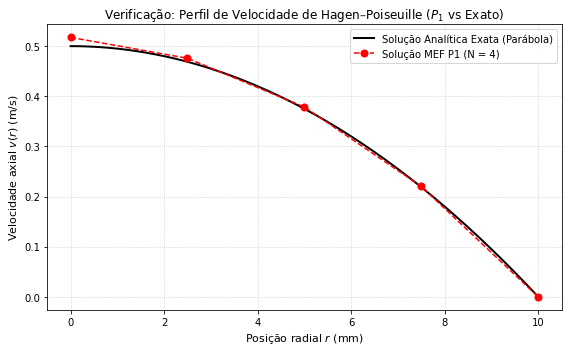

In [10]:
# 1. Função Python para a solução analítica exata
def v_exato_func(r_arr):
    return (G_val / (4.0 * eta_val)) * (a**2 - r_arr**2)

# Extração e ordenação das coordenadas dos DOFs e valores numéricos
r_dofs = V.tabulate_dof_coordinates()[:, 0]
ordem = np.argsort(r_dofs)
r_nos = r_dofs[ordem]
vh_nos = vh.x.array[ordem]
vex_nos = v_exato_func(r_nos)
erro_abs_nos = np.abs(vh_nos - vex_nos)

# 2. Exibição da Tabela de Valores nos Nós
print(f"{'Nó':<4} | {'r (m)':<10} | {'v_h (m/s)':<14} | {'v_exato (m/s)':<14} | {'Erro Abs (m/s)':<14}")
print("-" * 68)
for i in range(len(r_nos)):
    print(f"{i:<4} | {r_nos[i]:<10.5f} | {vh_nos[i]:<14.8f} | {vex_nos[i]:<14.8f} | {erro_abs_nos[i]:<14.2e}")

# 3. Medidas Quantitativas de Erro (Norma L2 contínua via integração UFL e Norma Infinito Nodal)
v_ex_ufl = (G / (4.0 * eta)) * (a**2 - r**2)

# Erro L2 ponderado e padrão no domínio contínuo (usando quadratura de grau elevado)
dx_alta = ufl.dx(metadata={"quadrature_degree": 6})
erro_L2 = np.sqrt(fem.assemble_scalar(fem.form((vh - v_ex_ufl)**2 * dx_alta)))
norma_L2_exata = np.sqrt(fem.assemble_scalar(fem.form(v_ex_ufl**2 * dx_alta)))
erro_L2_rel = erro_L2 / norma_L2_exata
erro_max_nodal = np.max(erro_abs_nos)

print("-" * 68)
print(f"Erro Máximo nos Nós (Norma L_inf nodal): {erro_max_nodal:.4e} m/s")
print(f"Erro Global Contínuo na Norma L2:        {erro_L2:.4e}")
print(f"Erro Relativo Global na Norma L2:        {erro_L2_rel * 100:.4f} %")

# 4. Gráfico Comparativo (Curva contínua exata vs Interpolação linear P1)
r_fino = np.linspace(0.0, a, 200)
v_fino = v_exato_func(r_fino)

plt.figure(figsize=(8, 5))
plt.plot(r_fino * 1000, v_fino, 'k-', linewidth=2, label="Solução Analítica Exata (Parábola)")
plt.plot(r_nos * 1000, vh_nos, 'ro--', linewidth=1.5, markersize=7, label=f"Solução MEF P1 (N = {N})")
plt.xlabel("Posição radial $r$ (mm)", fontsize=11)
plt.ylabel("Velocidade axial $v(r)$ (m/s)", fontsize=11)
plt.title("Verificação: Perfil de Velocidade de Hagen–Poiseuille ($P_1$ vs Exato)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 14. Estudo de malha com $P_1$

Resolva para

$$N=2,\;4,\;8,\;16,\;32.$$

Construa uma tabela de erros e discuta:

**1. Há convergência?**
* Sim, claramente. À medida que $N$ cresce de $2$ para $32$, tanto o erro na norma $L^2$ quanto o erro máximo nodal caem sistematicamente em direção a zero. 

**2. Como o erro varia com o refinamento?**
* O erro na norma $L^2$ apresenta convergência quadrática, isto é, $O(h^2)$ (ordem $\approx 2.00$ na última coluna da tabela). Isso significa que a cada vez que dobramos o número de elementos $N$ (reduzindo $h$ pela metade), o erro $L^2$ cai por um fator de aproximadamente $2^2 = 4$, em perfeita concordância com a estimativa teórica de Aubin–Nitsche para elementos finitos de grau $k=1$ ($\Vert{}v - v_h\Vert{}_{L^2} \le C h^{k+1}$). 

**3. Por que um único $P_1$ não reproduz exatamente o perfil?**
* Porque um elemento $P_1$ só gera uma linha reta ($v_h(r) = c_0 + c_1 r$), cuja segunda derivada é nula ($v_h'' = 0$), sendo incapaz de capturar a curvatura constante da parábola exata ($v'' = -G/(2\eta) \neq 0$).

**4. O que diferencia este caso do Couette?**
* No escoamento de Couette plano sem gradiente de pressão, a equação governante é $v'' = 0$, cuja solução exata é linear. Portanto, a solução exata pertence ao espaço $P_1$ e o erro de discretização é zero para qualquer $N \ge 1$. Em Hagen–Poiseuille, o termo fonte de pressão $G$ e a geometria cilíndrica geram uma solução quadrática que está fora de $P_1$.

N    | h (m)      | Erro L2      | Erro L2 Rel (%)  | Erro Max Nodal  | Ordem (L2)
--------------------------------------------------------------------------------
2    | 0.00500    | 1.8976e-03   | 5.1967           | 5.5556e-02      | ---       
4    | 0.00250    | 5.2207e-04   | 1.4297           | 1.7460e-02      | 1.86      
8    | 0.00125    | 1.3655e-04   | 0.3740           | 5.2651e-03      | 1.93      
16   | 0.00063    | 3.4897e-05   | 0.0956           | 1.5418e-03      | 1.97      
32   | 0.00031    | 8.8194e-06   | 0.0242           | 4.4184e-04      | 1.98      


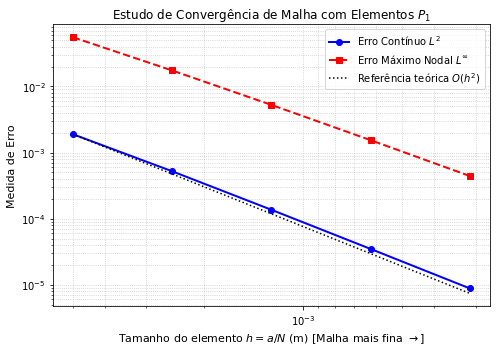

In [12]:
# Função geral para resolver o problema variacional para qualquer N, grau e parâmetros
def resolver_hagen_poiseuille(N_elem, grau_pol, raio=a, grad_p=G_val, visc=eta_val):
    dom = mesh.create_interval(MPI.COMM_WORLD, N_elem, [0.0, raio])
    V_esp = fem.functionspace(dom, ("Lagrange", grau_pol))
    
    v_tri = ufl.TrialFunction(V_esp)
    w_tst = ufl.TestFunction(V_esp)
    
    x_coord = ufl.SpatialCoordinate(dom)
    r_coord = x_coord[0]
    
    eta_c = fem.Constant(dom, PETSc.ScalarType(visc))
    G_c = fem.Constant(dom, PETSc.ScalarType(grad_p))
    
    a_f = eta_c * r_coord * ufl.Dx(v_tri, 0) * ufl.Dx(w_tst, 0) * ufl.dx
    l_f = G_c * r_coord * w_tst * ufl.dx
    
    fdim_loc = dom.topology.dim - 1
    parede_loc = mesh.locate_entities_boundary(dom, fdim_loc, lambda x: np.isclose(x[0], raio))
    dofs_loc = fem.locate_dofs_topological(V_esp, fdim_loc, parede_loc)
    bc_loc = fem.dirichletbc(PETSc.ScalarType(0.0), dofs_loc, V_esp)
    
    prob = LinearProblem(
        a_f, l_f, bcs=[bc_loc],
        petsc_options_prefix=f"hp_N{N_elem}_P{grau_pol}_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"}
    )
    vh_sol = prob.solve()
    
    # Solução exata simbólica em UFL para integração de alta precisão
    vex_ufl = (G_c / (4.0 * eta_c)) * (raio**2 - r_coord**2)
    dx_quad = ufl.dx(metadata={"quadrature_degree": 8})
    
    # Erro L2 contínuo e Norma L2 exata
    erro_L2 = np.sqrt(fem.assemble_scalar(fem.form((vh_sol - vex_ufl)**2 * dx_quad)))
    norma_L2 = np.sqrt(fem.assemble_scalar(fem.form(vex_ufl**2 * dx_quad)))
    erro_L2_rel = erro_L2 / norma_L2
    
    # Erro máximo nos DOFs (Norma L_inf nodal)
    r_dofs_loc = V_esp.tabulate_dof_coordinates()[:, 0]
    vex_dofs = (grad_p / (4.0 * visc)) * (raio**2 - r_dofs_loc**2)
    erro_inf = np.max(np.abs(vh_sol.x.array - vex_dofs))
    
    # Vazão numérica Qh = 2 * pi * int_0^a vh(r) * r dr
    Qh_val = 2.0 * np.pi * fem.assemble_scalar(fem.form(vh_sol * r_coord * dx_quad))
    
    return dom, V_esp, vh_sol, erro_L2, erro_L2_rel, erro_inf, Qh_val

# Executando o estudo de convergência para P1 com N = 2, 4, 8, 16, 32
Ns = [2, 4, 8, 16, 32]
resultados_P1 = []

print(f"{'N':<4} | {'h (m)':<10} | {'Erro L2':<12} | {'Erro L2 Rel (%)':<16} | {'Erro Max Nodal':<15} | {'Ordem (L2)':<10}")
print("-" * 80)

for idx, N_atual in enumerate(Ns):
    h_val = a / N_atual
    _, _, _, e_L2, e_L2_rel, e_inf, Qh = resolver_hagen_poiseuille(N_atual, grau_pol=1)
    
    # Cálculo da taxa (ordem) empírica de convergência p = log2(erro_anterior / erro_atual)
    if idx == 0:
        ordem_str = "---"
    else:
        e_L2_ant = resultados_P1[-1]["erro_L2"]
        ordem_p = np.log2(e_L2_ant / e_L2)
        ordem_str = f"{ordem_p:.2f}"
        
    resultados_P1.append({
        "N": N_atual, "h": h_val, "erro_L2": e_L2,
        "erro_L2_rel": e_L2_rel, "erro_inf": e_inf, "Qh": Qh
    })
    print(f"{N_atual:<4} | {h_val:<10.5f} | {e_L2:<12.4e} | {e_L2_rel*100:<16.4f} | {e_inf:<15.4e} | {ordem_str:<10}")

# Gráfico log-log de convergência do erro com o refinamento da malha
hs = [r["h"] for r in resultados_P1]
erros_L2 = [r["erro_L2"] for r in resultados_P1]
erros_inf = [r["erro_inf"] for r in resultados_P1]

plt.figure(figsize=(7, 5))
plt.loglog(hs, erros_L2, 'bo-', linewidth=2, label="Erro Contínuo $L^2$")
plt.loglog(hs, erros_inf, 'rs--', linewidth=2, label="Erro Máximo Nodal $L^\\infty$")
# Reta de referência O(h^2)
plt.loglog(hs, [erros_L2[0] * (h / hs[0])**2 for h in hs], 'k:', linewidth=1.5, label="Referência teórica $O(h^2)$")
plt.gca().invert_xaxis()  # Inverte eixo X para mostrar N crescendo da esquerda para a direita
plt.xlabel("Tamanho do elemento $h = a/N$ (m) [Malha mais fina $\\rightarrow$]", fontsize=11)
plt.ylabel("Medida de Erro", fontsize=11)
plt.title("Estudo de Convergência de Malha com Elementos $P_1$", fontsize=12)
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 15. Comparação $P_1\times P_2$

Repita parte do estudo com elementos de Lagrange $P_2$.

Como

$$v(r)=C_1-C_2r^2,$$

investigue:

$$\boxed{\text{qual é a relação entre a ordem da solução e a ordem do elemento finito?}}$$

* Quando o espaço de elementos finitos $P_k$ tem grau polinomial $k$ maior ou igual ao grau polinomial da solução analítica exata ($v_{\text{exato}} \in P_k$), a solução exata pertence ao subespaço de aproximação ($v_{\text{exato}} \in V_h$). Pelo Lema de Céa, como o método de Galerkin é uma projeção ortogonal na norma da energia, a solução numérica reproduz a solução analítica de forma exata (a menos da precisão de ponto flutuante da máquina, $\approx 10^{-16}$), mesmo com um único elemento ($N=1$)!Como $v(r) = C_1 - C_2 r^2$ tem grau 2, o elemento $P_2$ atinge erro da ordem de $10^{-16}$ já para $N=1$.

Apresente evidências numéricas.

Comparação Direta: Elementos Lineares (P1) vs Quadráticos (P2)
N    | Erro L2 (P1)    | Erro L2 (P2)    | Erro Max Nodal (P2) 
-----------------------------------------------------------------
1    | 6.0858e-03      | 1.6252e-17      | 2.2204e-16          
2    | 1.8976e-03      | 4.3576e-17      | 7.2164e-16          
4    | 5.2207e-04      | 1.0681e-16      | 1.7208e-15          
8    | 1.3655e-04      | 6.4598e-17      | 1.2768e-15          


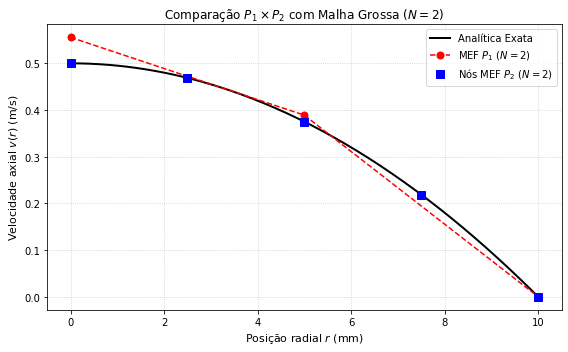

In [13]:
# Resolvendo com elementos quadráticos P2 para N = 1, 2, 4, 8
Ns_P2 = [1, 2, 4, 8]

print("Comparação Direta: Elementos Lineares (P1) vs Quadráticos (P2)")
print(f"{'N':<4} | {'Erro L2 (P1)':<15} | {'Erro L2 (P2)':<15} | {'Erro Max Nodal (P2)':<20}")
print("-" * 65)

for N_teste in Ns_P2:
    _, _, _, e_L2_p1, _, _, _ = resolver_hagen_poiseuille(N_teste, grau_pol=1)
    _, _, _, e_L2_p2, _, e_inf_p2, _ = resolver_hagen_poiseuille(N_teste, grau_pol=2)
    print(f"{N_teste:<4} | {e_L2_p1:<15.4e} | {e_L2_p2:<15.4e} | {e_inf_p2:<20.4e}")

# Comparação visual para malha super grossa (N = 2 elementos)
_, V_p1, vh_p1, _, _, _, _ = resolver_hagen_poiseuille(2, grau_pol=1)
dom_p2, V_p2, vh_p2, _, _, _, _ = resolver_hagen_poiseuille(2, grau_pol=2)

r_p1 = V_p1.tabulate_dof_coordinates()[:, 0]
ord_p1 = np.argsort(r_p1)

r_p2 = V_p2.tabulate_dof_coordinates()[:, 0]
ord_p2 = np.argsort(r_p2)

r_fino = np.linspace(0.0, a, 200)
plt.figure(figsize=(8, 5))
plt.plot(r_fino * 1000, v_exato_func(r_fino), 'k-', linewidth=2, label="Analítica Exata")
plt.plot(r_p1[ord_p1] * 1000, vh_p1.x.array[ord_p1], 'ro--', linewidth=1.5, markersize=7, label="MEF $P_1$ ($N=2$)")
plt.plot(r_p2[ord_p2] * 1000, vh_p2.x.array[ord_p2], 'bs', markersize=8, label="Nós MEF $P_2$ ($N=2$)")
plt.xlabel("Posição radial $r$ (mm)", fontsize=11)
plt.ylabel("Velocidade axial $v(r)$ (m/s)", fontsize=11)
plt.title("Comparação $P_1 \\times P_2$ com Malha Grossa ($N = 2$)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

## 16. Vazão numérica

Como

$$dA=2\pi r\,dr,$$

calcule

$$\boxed{Q_h=2\pi\int_0^a v_h(r)r\,dr}$$

e compare com

$$Q_{\rm exato}=\frac{\pi a^4G}{8\eta}.$$

Apresente $Q_h$, $Q_{\rm exato}$ e o erro relativo para diferentes malhas. Explique a origem geométrica do fator $2\pi r$.

* Como a velocidade depende apenas da distância radial $r$ ao centro do tubo, o fluxo através da seção transversal circular de raio $a$ pode ser decomposto em anéis concêntricos infinitesimais de raio $r$ e espessura $dr$. Quando "desenrolamos" um anel de raio $r$, ele forma uma tira retangular de comprimento igual ao perímetro da circunferência ($2\pi r$) e largura $dr$, cuja área é $dA = 2\pi r \, dr$. Assim, a integral de superfície $\iint_A v \, dA$ reduz-se à integral simples unidimensional $\int_0^a v(r) (2\pi r \, dr) = 2\pi \int_0^a v(r) r \, dr$. 

In [14]:
# Vazão analítica exata pela lei de Hagen-Poiseuille
Q_exato = (np.pi * (a**4) * G_val) / (8.0 * eta_val)
print(f"Vazão Analítica Exata (Q_exato): {Q_exato:.8e} m^3/s ({Q_exato * 1e6:.4f} mL/s)\n")

print(f"{'Malha (N)':<10} | {'Q_h (P1) [m^3/s]':<18} | {'Erro Rel P1 (%)':<16} | {'Q_h (P2) [m^3/s]':<18} | {'Erro Rel P2 (%)':<16}")
print("-" * 86)

for r_p1 in resultados_P1:
    N_atual = r_p1["N"]
    Qh_p1 = r_p1["Qh"]
    erro_rel_Q_p1 = abs(Qh_p1 - Q_exato) / Q_exato * 100.0
    
    # Calculando também com P2 para comparar a precisão na vazão
    _, _, _, _, _, _, Qh_p2 = resolver_hagen_poiseuille(N_atual, grau_pol=2)
    erro_rel_Q_p2 = abs(Qh_p2 - Q_exato) / Q_exato * 100.0
    
    print(f"{N_atual:<10} | {Qh_p1:<18.8e} | {erro_rel_Q_p1:<16.4f} | {Qh_p2:<18.8e} | {erro_rel_Q_p2:<16.4e}")

Vazão Analítica Exata (Q_exato): 7.85398163e-05 m^3/s (78.5398 mL/s)

Malha (N)  | Q_h (P1) [m^3/s]   | Erro Rel P1 (%)  | Q_h (P2) [m^3/s]   | Erro Rel P2 (%) 
--------------------------------------------------------------------------------------
2          | 7.56309343e-05     | 3.7037           | 7.85398163e-05     | 8.6278e-14      
4          | 7.77502626e-05     | 1.0053           | 7.85398163e-05     | 1.8981e-13      
8          | 7.83374393e-05     | 0.2577           | 7.85398163e-05     | 1.8981e-13      
16         | 7.84888413e-05     | 0.0649           | 7.85398163e-05     | 1.1906e-12      
32         | 7.85270445e-05     | 0.0163           | 7.85398163e-05     | 1.2424e-12      


## 17. Investigação física

Investigue numericamente

$$Q\propto(p_1-p_2),\qquad Q\propto\frac1\eta,\qquad Q\propto a^4.$$

### Experimento obrigatório
Aumente o raio em **10%**, mantendo os demais parâmetros constantes.

Antes de executar:
1. faça a previsão teórica da variação percentual de $Q$ ao aumentar o raio em $10\%$;
* Pela lei de Hagen–Poiseuille, $Q \propto a^4$. Se o novo raio é $a_{\text{novo}} = 1.10 \, a$, a nova vazão será:

   $Q_{\text{novo}} = Q_{\text{original}} \times (1.10)^4 = 1.4641$ \, $Q_{\text{original}}$ Portanto, um aumento de apenas $10\%$ no raio provoca um aumento teórico de $46.41\%$ na vazão volumétrica!

2. execute o experimento;
3. compare teoria e resultado numérico;
4. explique o resultado.
* Por que a sensibilidade ao raio é tão extrema ($a^4$)? Porque o raio atua duplamente a favor do escoamento:

    * 1. Efeito geométrico direto ($a^2$): A área da seção transversal por onde o fluido passa cresce com o quadrado do raio ($A = \pi a^2$).
    * 2. Efeito dinâmico viscoso ($a^2$): Ao afastar as paredes estacionárias do centro do tubo, o efeito de frenagem viscosa diminui e a própria velocidade máxima e média do escoamento dentro do tubo também crescem com o quadrado do raio ($v_{\text{máx}} = \frac{G}{4\eta}a^2$). O produto $(A \propto a^2) \times (v_{\text{média}} \propto a^2)$ resulta na dependência de quarta potência ($Q \propto a^4$). (É por isso que, na medicina, um pequeno acúmulo de gordura que reduza o raio de uma artéria em $10\%$ reduz o fluxo sanguíneo em quase $35\%$, exigindo muito mais pressão do coração!).

=== EXPERIMENTO OBRIGATÓRIO: AUMENTO DE 10% NO RAIO (a_novo = 1.10 * a) ===
Previsão Teórica: (1.10)^4 - 1 = +46.4100 %
Resultado Numérico MEF (P1, N=32): +46.4100 %
Resultado Numérico MEF (P2, N=32): +46.4100 %



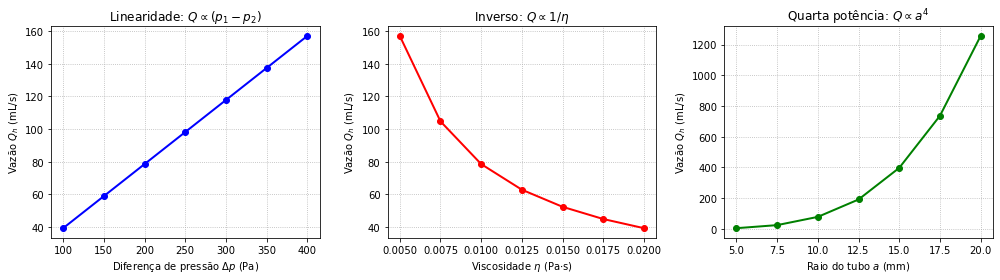

In [15]:
# 1. Experimento Obrigatório: Aumento de 10% no raio (usando N = 32 em P1 e P2)
a_novo = 1.10 * a
Q_exato_original = (np.pi * (a**4) * G_val) / (8.0 * eta_val)
Q_exato_novo = (np.pi * (a_novo**4) * G_val) / (8.0 * eta_val)

_, _, _, _, _, _, Qh_orig_P1 = resolver_hagen_poiseuille(32, grau_pol=1, raio=a)
_, _, _, _, _, _, Qh_novo_P1 = resolver_hagen_poiseuille(32, grau_pol=1, raio=a_novo)

_, _, _, _, _, _, Qh_orig_P2 = resolver_hagen_poiseuille(32, grau_pol=2, raio=a)
_, _, _, _, _, _, Qh_novo_P2 = resolver_hagen_poiseuille(32, grau_pol=2, raio=a_novo)

var_teorica_pct = ((Q_exato_novo - Q_exato_original) / Q_exato_original) * 100.0
var_num_P1_pct = ((Qh_novo_P1 - Qh_orig_P1) / Qh_orig_P1) * 100.0
var_num_P2_pct = ((Qh_novo_P2 - Qh_orig_P2) / Qh_orig_P2) * 100.0

print("=== EXPERIMENTO OBRIGATÓRIO: AUMENTO DE 10% NO RAIO (a_novo = 1.10 * a) ===")
print(f"Previsão Teórica: (1.10)^4 - 1 = +{var_teorica_pct:.4f} %")
print(f"Resultado Numérico MEF (P1, N=32): +{var_num_P1_pct:.4f} %")
print(f"Resultado Numérico MEF (P2, N=32): +{var_num_P2_pct:.4f} %\n")

# 2. Investigação paramétrica: Q vs (p1-p2), Q vs 1/eta, e Q vs a^4
fatores = np.linspace(0.5, 2.0, 7)
Q_var_dp = []
Q_var_eta = []
Q_var_a = []

for f in fatores:
    # Variando Delta p (G proporcional a Delta p)
    _, _, _, _, _, _, q_dp = resolver_hagen_poiseuille(16, 2, raio=a, grad_p=f*G_val, visc=eta_val)
    Q_var_dp.append(q_dp * 1e6) # em mL/s
    
    # Variando viscosidade eta
    _, _, _, _, _, _, q_eta = resolver_hagen_poiseuille(16, 2, raio=a, grad_p=G_val, visc=f*eta_val)
    Q_var_eta.append(q_eta * 1e6)
    
    # Variando raio a
    _, _, _, _, _, _, q_a = resolver_hagen_poiseuille(16, 2, raio=f*a, grad_p=G_val, visc=eta_val)
    Q_var_a.append(q_a * 1e6)

fig, axs = plt.subplots(1, 3, figsize=(14, 4))

axs[0].plot(fatores * (p1 - p2), Q_var_dp, 'bo-', linewidth=2)
axs[0].set_xlabel("Diferença de pressão $\\Delta p$ (Pa)")
axs[0].set_ylabel("Vazão $Q_h$ (mL/s)")
axs[0].set_title("Linearidade: $Q \\propto (p_1 - p_2)$")
axs[0].grid(True, linestyle=":")

axs[1].plot(fatores * eta_val, Q_var_eta, 'ro-', linewidth=2)
axs[1].set_xlabel("Viscosidade $\\eta$ (Pa$\\cdot$s)")
axs[1].set_ylabel("Vazão $Q_h$ (mL/s)")
axs[1].set_title("Inverso: $Q \\propto 1/\\eta$")
axs[1].grid(True, linestyle=":")

axs[2].plot(fatores * a * 1000, Q_var_a, 'go-', linewidth=2)
axs[2].set_xlabel("Raio do tubo $a$ (mm)")
axs[2].set_ylabel("Vazão $Q_h$ (mL/s)")
axs[2].set_title("Quarta potência: $Q \\propto a^4$")
axs[2].grid(True, linestyle=":")

plt.tight_layout()
plt.show()